Dataset loaded successfully!
CSV file: Customer Churn.csv
Dataset shape: (3150, 14)

Column names:
['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Churn']

First five rows:


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0



Number of instances: 3150
Number of input features: 13
Target column: Churn

Class distribution:
Churn
0    2655
1     495
Name: count, dtype: int64

Class proportions:
Churn
0    0.8429
1    0.1571
Name: proportion, dtype: float64

Training samples: 2520
Testing samples: 630

Training Logistic Regression...
Logistic Regression completed.

Training Decision Tree...
Decision Tree completed.

Training K-Nearest Neighbors...
K-Nearest Neighbors completed.

Training Gaussian Naive Bayes...
Gaussian Naive Bayes completed.

Training Support Vector Machine...
Support Vector Machine completed.

========== MODEL PERFORMANCE COMPARISON ==========


,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC Score
Model,,,,,,
Logistic Regression,0.8968,0.9208,0.8400,0.4242,0.5638,0.5509
Decision Tree,0.9270,0.8673,0.7732,0.7576,0.7653,0.7221
K-Nearest Neighbors,0.9524,0.9677,0.8632,0.8283,0.8454,0.8175
Gaussian Naive Bayes,0.7381,0.8986,0.3648,0.8990,0.5190,0.4536
Support Vector Machine,0.9238,0.9544,0.9636,0.5354,0.6883,0.6854


Results saved to iranian_churn_model_results.csv


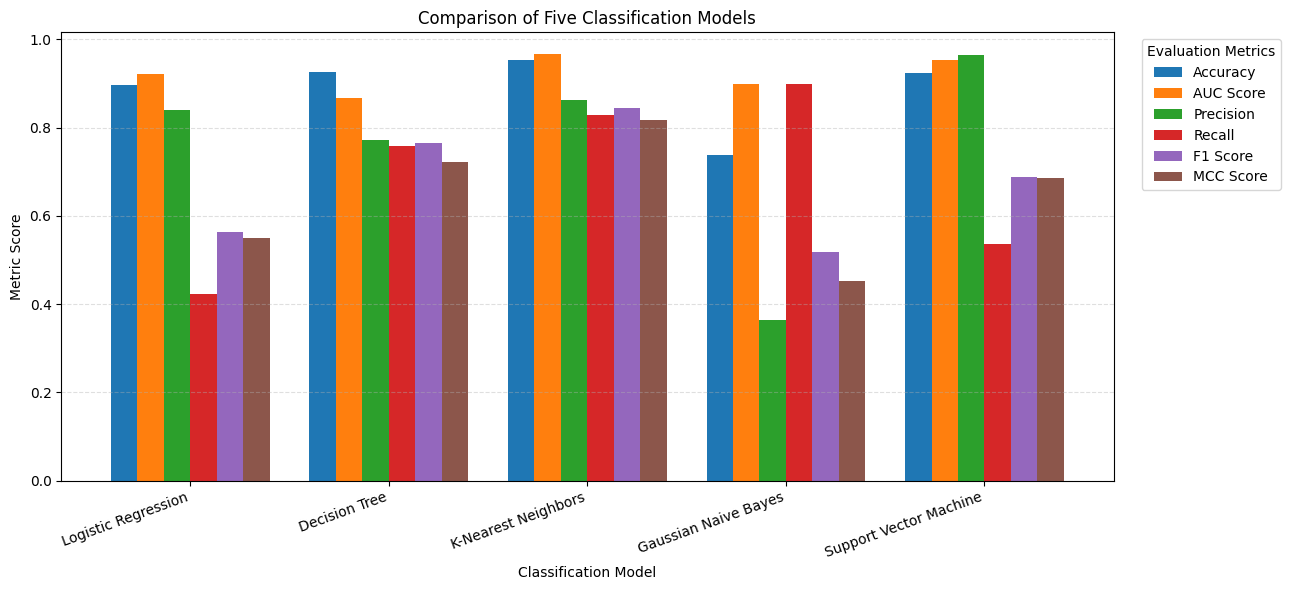


========== BEST MODEL BY METRIC ==========
Accuracy: K-Nearest Neighbors (Score = 0.9524)
AUC Score: K-Nearest Neighbors (Score = 0.9677)
Precision: Support Vector Machine (Score = 0.9636)
Recall: Gaussian Naive Bayes (Score = 0.8990)
F1 Score: K-Nearest Neighbors (Score = 0.8454)
MCC Score: K-Nearest Neighbors (Score = 0.8175)

========== Logistic Regression ==========

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.98      0.94       531
       Churn       0.84      0.42      0.56        99

    accuracy                           0.90       630
   macro avg       0.87      0.70      0.75       630
weighted avg       0.89      0.90      0.88       630

Confusion matrix:
[[523   8]
 [ 57  42]]

========== Decision Tree ==========

Classification report:
              precision    recall  f1-score   support

    No Churn       0.95      0.96      0.96       531
       Churn       0.77      0.76      0.77        99

    accur

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# MACHINE LEARNING CLASSIFICATION ASSIGNMENT
# Dataset: UCI Iranian Churn Dataset
#
# Models:
# 1. Logistic Regression
# 2. Decision Tree Classifier
# 3. K-Nearest Neighbors
# 4. Gaussian Naive Bayes
# 5. Support Vector Machine
#
# Metrics:
# Accuracy, AUC, Precision, Recall, F1, MCC
# ============================================================

# 1. IMPORT LIBRARIES

import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 2. DOWNLOAD AND LOAD DATASET DIRECTLY FROM UCI
# ------------------------------------------------------------

url = (
    "https://archive.ics.uci.edu/static/public/"
    "563/iranian+churn+dataset.zip"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError("No CSV file found inside the ZIP archive.")

    # The UCI archive contains the customer churn CSV
    with z.open(csv_files[0]) as file:
        df = pd.read_csv(file)

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("CSV file:", csv_files[0])
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

# ------------------------------------------------------------
# 3. PREPARE FEATURES AND TARGET
# ------------------------------------------------------------

# Find target column without depending on capitalization
target_col = next(
    (col for col in df.columns if col.strip().lower() == "churn"),
    None
)

if target_col is None:
    raise ValueError(
        "Target column 'Churn' was not found. "
        "Check the printed column names."
    )

# Convert all feature columns to numeric values
X = df.drop(columns=[target_col]).copy()
X = X.apply(pd.to_numeric, errors="coerce")

# Convert target to numeric values
y = pd.to_numeric(df[target_col], errors="coerce")

# Remove rows with missing target values
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

# Replace infinite values and impute missing feature values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

# Ensure binary target is encoded as 0 and 1
unique_classes = sorted(y.unique())

if len(unique_classes) != 2:
    raise ValueError(
        f"Expected a binary target, but found {unique_classes}"
    )

if unique_classes != [0, 1]:
    y = y.map({unique_classes[0]: 0, unique_classes[1]: 1})

y = y.astype(int)

print("\nNumber of instances:", len(X))
print("Number of input features:", X.shape[1])
print("Target column:", target_col)

print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nClass proportions:")
print(y.value_counts(normalize=True).sort_index().round(4))

# ------------------------------------------------------------
# 4. SPLIT INTO TRAINING AND TESTING DATA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ------------------------------------------------------------
# 5. DEFINE ALL FIVE CLASSIFICATION MODELS
# ------------------------------------------------------------

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Gaussian Naive Bayes": make_pipeline(
        StandardScaler(),
        GaussianNB()
    ),

    "Support Vector Machine": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        )
    )
}

# ------------------------------------------------------------
# 6. TRAIN AND EVALUATE ALL FIVE MODELS
# ------------------------------------------------------------

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train the model
    model.fit(X_train, y_train)

    # Predict class labels and probabilities
    y_pred = model.predict(X_test)

    # Probability of the positive class: churn = 1
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate all six evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_prob)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC Score": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC Score": mcc
    })

    trained_models[name] = model

    print(f"{name} completed.")

# ------------------------------------------------------------
# 7. DISPLAY COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results).set_index("Model")

print("\n========== MODEL PERFORMANCE COMPARISON ==========")
display(results_df.round(4))

# Save results to CSV
results_df.to_csv("iranian_churn_model_results.csv")

print("Results saved to iranian_churn_model_results.csv")

# ------------------------------------------------------------
# 8. PLOT COMPARISON OF THE SIX METRICS
# ------------------------------------------------------------

ax = results_df.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Comparison of Five Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Metric Score")
plt.xticks(rotation=20, ha="right")
plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. IDENTIFY THE BEST MODEL FOR EACH METRIC
# ------------------------------------------------------------

print("\n========== BEST MODEL BY METRIC ==========")

for metric in results_df.columns:
    best_model = results_df[metric].idxmax()
    best_score = results_df[metric].max()

    print(
        f"{metric}: {best_model} "
        f"(Score = {best_score:.4f})"
    )

# ------------------------------------------------------------
# 10. DETAILED CLASSIFICATION REPORTS
# ------------------------------------------------------------

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print(f"\n========== {name} ==========")

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )

    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

# ------------------------------------------------------------
# 11. DOWNLOAD THE RESULTS TABLE IN GOOGLE COLAB
# ------------------------------------------------------------

from google.colab import files

files.download("iranian_churn_model_results.csv")
